<a href="https://colab.research.google.com/github/caiohenry-jpg/CalculoNumerico/blob/main/Atv19_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MÉTODO DE GAUSS-SEIDEL
Número de iterações: 6
x = 1.0000000269
y = 1.9999999762
z = -1.0000000078
Erro final entre iterações: 1.2626069386e-06

TABELA DE ITERAÇÕES
 k            x(k)            y(k)            z(k)             Erro
 0    0.0000000000    0.0000000000    0.0000000000              ---
 1    0.6000000000    2.0545454545   -0.9145454545   2.05454545e+00
 2    0.9883636364    2.0067107438   -0.9970016529   3.88363636e-01
 3    1.0000714050    2.0002790684   -0.9999863742   1.17077686e-02
 4    1.0000251817    2.0000035280   -1.0000046835   2.75540414e-04
 5    1.0000012895    1.9999996915   -1.0000002888   2.38921647e-05
 6    1.0000000269    1.9999999762   -1.0000000078   1.26260694e-06


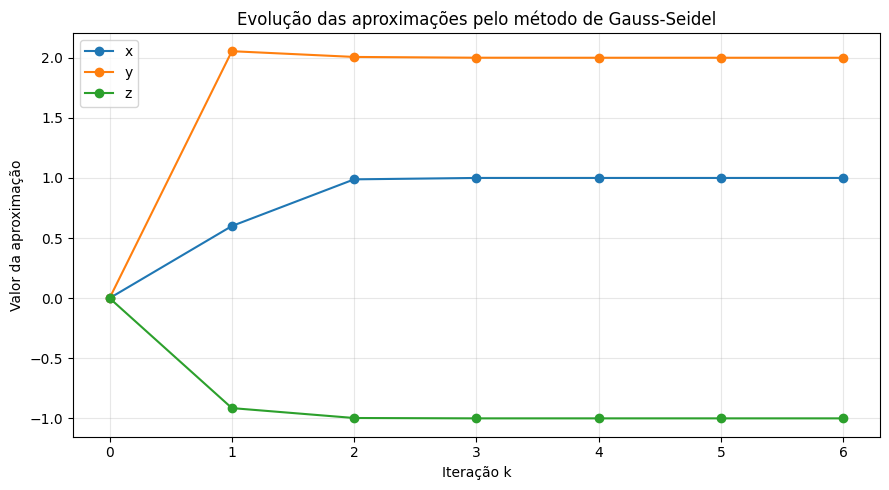

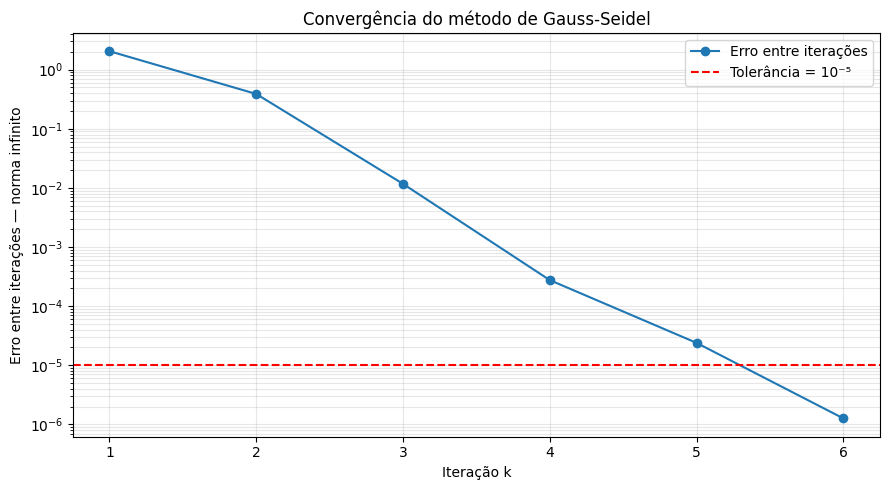

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sistema A @ v = b
A = np.array([
    [10., -1.,  2.],
    [-1., 11., -1.],
    [ 2., -1., 10.]
])
b = np.array([6., 22., -10.])

# Aproximação inicial e critério de parada
v = np.zeros(3)
tolerancia = 1e-5
historico = [(0, *v, np.nan)]

for k in range(1, 1001):
    anterior = v.copy()

    for i in range(3):
        # Valores já atualizados nesta iteração
        soma_nova = A[i, :i] @ v[:i]

        # Valores da iteração anterior
        soma_antiga = A[i, i + 1:] @ anterior[i + 1:]

        v[i] = (b[i] - soma_nova - soma_antiga) / A[i, i]

    erro = np.max(np.abs(v - anterior))
    historico.append((k, *v, erro))

    if erro < tolerancia:
        break
else:
    raise RuntimeError("O método atingiu o limite de iterações.")

print("MÉTODO DE GAUSS-SEIDEL")
print(f"Número de iterações: {k}")
print(f"x = {v[0]:.10f}")
print(f"y = {v[1]:.10f}")
print(f"z = {v[2]:.10f}")
print(f"Erro final entre iterações: {erro:.10e}")

print("\nTABELA DE ITERAÇÕES")
print(f"{'k':>2} {'x(k)':>15} {'y(k)':>15} {'z(k)':>15} {'Erro':>16}")

for j, x, y, z, e in historico:
    erro_texto = "---" if np.isnan(e) else f"{e:.8e}"
    print(
        f"{j:2d} {x:15.10f} {y:15.10f} "
        f"{z:15.10f} {erro_texto:>16}"
    )

dados = np.array(historico)

# Gráfico 1: aproximações
plt.figure(figsize=(9, 5))

for coluna, nome in enumerate(["x", "y", "z"], start=1):
    plt.plot(
        dados[:, 0],
        dados[:, coluna],
        marker="o",
        label=nome
    )

plt.title("Evolução das aproximações pelo método de Gauss-Seidel")
plt.xlabel("Iteração k")
plt.ylabel("Valor da aproximação")
plt.xticks(dados[:, 0])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("aproximacoes.png", dpi=200)
plt.show()

# Gráfico 2: erro entre iterações em escala logarítmica
plt.figure(figsize=(9, 5))

plt.semilogy(
    dados[1:, 0],
    dados[1:, 4],
    marker="o",
    label="Erro entre iterações"
)

plt.axhline(
    tolerancia,
    color="red",
    linestyle="--",
    label="Tolerância = 10⁻⁵"
)

plt.title("Convergência do método de Gauss-Seidel")
plt.xlabel("Iteração k")
plt.ylabel("Erro entre iterações — norma infinito")
plt.xticks(dados[1:, 0])
plt.grid(which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("erros.png", dpi=200)
plt.show()